# 02 · Exploratory analysis — where the energy and the money go
Runs on the **cleaned** tables in `data/clean/` (see `src/clean_data.py`). Covers: harmonised hourly usage for all three hotels
(including the engineered Gurugram hourly feature), load shapes, weather / occupancy / event drivers, equipment breakdown,
chiller-plant efficiency, bill breakdown, and Gurugram peak demand.

Anomaly labels are **not** used here.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from features import gurugram_hourly, unified_hourly, cooling_degree_hours, SITES, ROOMS, CONTRACT_KVA

CLEAN = ROOT / "data" / "clean"
pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
COL = {"GGN": "#1f77b4", "JAI": "#d95f02", "GOA": "#1b9e77"}
ld = lambda n: pd.read_parquet(CLEAN / f"{n}.parquet")

g15 = ld("meter_ggn_15min")
sub_g = ld("sub_ggn_hourly"); sub_jg = ld("sub_jai_goa_hourly")
weather = ld("weather_hourly"); occ = ld("occupancy_daily"); events = ld("events"); bills = ld("monthly_bills")
print("loaded cleaned tables")

loaded cleaned tables


## 1 · Engineered feature: Gurugram hourly usage
Gurugram's incomer is 15-minute; Jaipur and Goa are hourly. `gurugram_hourly()` (in `src/features.py`) collapses it to the same hourly schema:
energy columns are **summed**, `kva_max_in_hour` is the **max** 15-min kVA (same definition as the other two meters, and what the utility bills as MD),
and `power_factor` is hourly kWh ÷ kVAh. Diesel energy is added into `kw_avg`/`total_kwh` (as Jaipur/Goa do), and data-quality flags carry through.

In [2]:
ggn_h = gurugram_hourly(g15)
print(ggn_h.shape, "| columns:", list(ggn_h.columns))
display(ggn_h.head(4))

# Validation 1: energy conserved (hourly sums == 15-min sums)
print("energy conserved:", np.isclose(ggn_h.grid_kwh.sum(), g15.grid_kwh.sum()), np.isclose(ggn_h.dg_kwh.sum(), g15.dg_kwh.sum()))
# Validation 2: hourly max kVA monthly max == monthly MD on the bills
md = ggn_h.groupby(ggn_h.timestamp.dt.to_period("M").astype(str)).kva_max_in_hour.max()
bill_md = bills[bills.site == "GGN"].set_index("billing_month").recorded_md_kva
print("max |hourly-derived MD - billed MD| kVA:", float((md - bill_md).abs().max().round(1)))
# Validation 3: agrees with the independent sub-meters on non-DG, non-fault hours
s = sub_g.set_index("timestamp")[[c for c in sub_g.columns if c.endswith("_kw") and c != "kw_per_tr"]].sum(axis=1)
v = ggn_h.set_index("timestamp").join(s.rename("subs")).query("~is_dg and ~has_meter_fault")
print(f"hourly main vs sub-meter total: median diff {((v.subs-v.kw_avg)/v.kw_avg).median():.2%}, 95% within ±{((v.subs-v.kw_avg)/v.kw_avg).abs().quantile(.95):.1%}")

(8760, 14) | columns: ['timestamp', 'grid_kwh', 'grid_kvah', 'dg_kwh', 'kva_max_in_hour', 'dg_intervals', 'fault_intervals', 'n_intervals', 'kw_avg', 'power_factor', 'total_kwh', 'is_dg', 'has_meter_fault', 'exclude_from_model']


,timestamp,grid_kwh,grid_kvah,dg_kwh,kva_max_in_hour,dg_intervals,fault_intervals,n_intervals,kw_avg,power_factor,total_kwh,is_dg,has_meter_fault,exclude_from_model
0,2025-10-01 00:00:00,294.66,303.84,0.00,318.40,0,0,4,294.66,0.97,294.66,False,False,False
1,2025-10-01 01:00:00,296.79,305.00,0.00,327.90,0,0,4,296.79,0.97,296.79,False,False,False
2,2025-10-01 02:00:00,288.63,294.96,0.00,311.90,0,0,4,288.63,0.98,288.63,False,False,False
3,2025-10-01 03:00:00,283.89,291.75,0.00,305.60,0,0,4,283.89,0.97,283.89,False,False,False


energy conserved: True True
max |hourly-derived MD - billed MD| kVA: 0.5
hourly main vs sub-meter total: median diff 0.01%, 95% within ±3.5%


In [3]:
# One comparable hourly table for the three hotels
U = unified_hourly()
U["date"] = U.timestamp.dt.normalize(); U["hour"] = U.timestamp.dt.hour; U["month"] = U.timestamp.dt.to_period("M").astype(str)
U["dow"] = U.timestamp.dt.day_of_week; U["weekend"] = U.dow >= 5
U["rooms"] = U.site.map(ROOMS)
U["kwh_per_room"] = U.total_kwh / U.rooms
print(U.groupby("site").agg(rows=("total_kwh", "size"), mean_kw=("total_kwh", "mean"), p95_kw=("total_kwh", lambda x: x.quantile(.95)),
                            max_kw=("total_kwh", "max"), dg_hours=("is_dg", "sum")).round(0))

      rows  mean_kw  p95_kw  max_kw  dg_hours
site                                         
GGN   8760   474.00  665.00  998.00        49
GOA   8760   242.00  324.00  388.00        64
JAI   8760   250.00  331.00  388.00        42


## 2 · Energy per occupied room-night (check against the brief: 73.3 / 54.1 / 61.6)

,total_kwh,grid_kwh,room_nights,kWh/occ-room-night (total),kWh/occ-room-night (grid only),brief
site,,,,,,
GGN,"4,148,022.80","4,130,803.40",56574,73.30,73.00,73.30
GOA,"2,120,067.20","2,109,792.10",34422,61.60,61.30,61.60
JAI,"2,190,517.10","2,183,216.50",40487,54.10,53.90,54.10


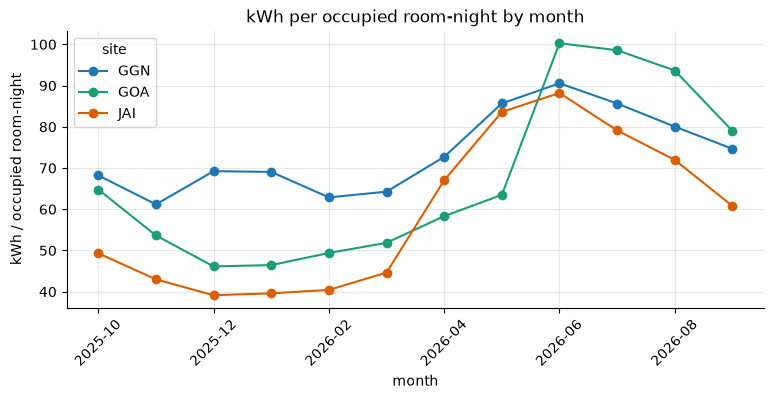

In [4]:
daily = U.groupby(["site", "date"]).agg(total_kwh=("total_kwh", "sum"), grid_kwh=("grid_kwh", "sum"), grid_kvah=("grid_kvah", "sum"),
                                         dg_kwh=("dg_kwh", "sum"), max_kva=("kva_max_in_hour", "max"),
                                         excl=("exclude_from_model", "max")).reset_index()
daily = daily.merge(occ.assign(date=pd.to_datetime(occ.date)), on=["site", "date"], how="left")
w = weather.assign(date=weather.timestamp.dt.normalize())
wd = w.groupby(["site", "date"]).agg(temp_mean=("temp_c", "mean"), temp_max=("temp_c", "max"), temp_min=("temp_c", "min"),
                                     rh_mean=("rel_humidity_pct", "mean"), rain_mm=("rain_mm", "sum")).reset_index()
daily = daily.merge(wd, on=["site", "date"], how="left")
ev = events.assign(date=pd.to_datetime(events.date))
eg = ev.groupby(["site", "date"]).agg(event_guests=("guests", "sum"), n_events=("guests", "size")).reset_index()
daily = daily.merge(eg, on=["site", "date"], how="left").fillna({"event_guests": 0, "n_events": 0})
daily["month"] = daily.date.dt.to_period("M").astype(str)

t = daily.groupby("site").agg(total_kwh=("total_kwh", "sum"), grid_kwh=("grid_kwh", "sum"), room_nights=("rooms_sold", "sum"))
t["kWh/occ-room-night (total)"] = t.total_kwh / t.room_nights
t["kWh/occ-room-night (grid only)"] = t.grid_kwh / t.room_nights
t["brief"] = pd.Series({"GGN": 73.3, "JAI": 54.1, "GOA": 61.6})
display(t.round(1))
m = daily.groupby(["month", "site"]).apply(lambda d: d.total_kwh.sum() / d.rooms_sold.sum(), include_groups=False).unstack()
ax = m.plot(figsize=(9, 3.6), marker="o", color=[COL[c] for c in m.columns], title="kWh per occupied room-night by month")
ax.set_ylabel("kWh / occupied room-night"); plt.xticks(rotation=45); plt.show()

## 3 · Load shapes — average day by hotel, season and day type

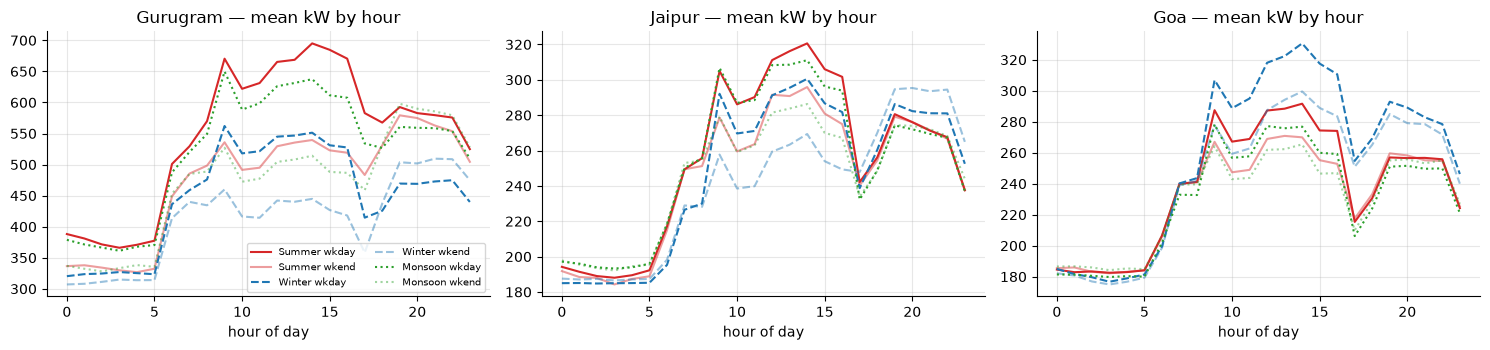

,night base (01-05) kW,evening peak (18-22) kW,daily mean kW,peak/base
site,,,,
GGN,330.10,518.20,473.40,1.60
GOA,181.10,262.20,242.00,1.40
JAI,187.20,274.80,250.10,1.50


In [5]:
season = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Summer", 6: "Summer", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon", 10: "Autumn", 11: "Autumn"}
U["season"] = U.timestamp.dt.month.map(season)
ok = U[~U.exclude_from_model & ~U.is_dg]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=False)
for ax, sc in zip(axes, ["GGN", "JAI", "GOA"]):
    for sn, ls in (("Summer", "-"), ("Winter", "--"), ("Monsoon", ":")):
        for wk, a in ((False, 1), (True, .45)):
            d = ok[(ok.site == sc) & (ok.season == sn) & (ok.weekend == wk)].groupby("hour").kw_avg.mean()
            ax.plot(d.index, d.values, ls, color={"Summer": "#d62728", "Winter": "#1f77b4", "Monsoon": "#2ca02c"}[sn], alpha=a,
                    label=f"{sn} {'wkend' if wk else 'wkday'}")
    ax.set_title(f"{SITES[sc]} — mean kW by hour"); ax.set_xlabel("hour of day")
axes[0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

# Night base load, evening peak vs overnight, per site
prof = ok.groupby(["site", "hour"]).kw_avg.mean().unstack(0)
summary = pd.DataFrame({"night base (01-05) kW": prof.loc[1:4].mean(), "evening peak (18-22) kW": prof.loc[18:21].mean(), "daily mean kW": prof.mean()})
summary["peak/base"] = summary.iloc[:, 1] / summary.iloc[:, 0]
display(summary.round(1))

## 4 · What drives daily load: temperature, humidity, occupancy, events, day type
Daily kWh regressed on cooling degree hours (CDH) at a range of base temperatures, plus rooms sold, event guests and weekend.
The base temperature with the best R² is picked per hotel; then humidity is tested as an add-on.

In [6]:
def ols(X, y):
    X = np.column_stack([np.ones(len(X)), X]); b, *_ = np.linalg.lstsq(X, y, rcond=None)
    r = y - X @ b; return b, 1 - (r ** 2).sum() / ((y - y.mean()) ** 2).sum()

cdh_all = {}
hw = w.copy()
best = {}
rows = []
for sc in ["GGN", "JAI", "GOA"]:
    d0 = daily[(daily.site == sc) & ~daily.excl & (daily.dg_kwh == 0)].copy()
    hh = hw[hw.site == sc]
    for base in range(14, 29, 2):
        cdh = cooling_degree_hours(hh.temp_c, base).groupby(hh.timestamp.dt.normalize()).sum().rename("cdh")
        d = d0.merge(cdh, left_on="date", right_index=True)
        X = d[["cdh", "rooms_sold", "event_guests"]].assign(weekend=(d.date.dt.day_of_week >= 5).astype(float)).values
        _, r2 = ols(X, d.total_kwh.values); rows.append((sc, base, r2))
res = pd.DataFrame(rows, columns=["site", "base_C", "R2"]).pivot(index="base_C", columns="site", values="R2")
display(res.round(3)); best = res.idxmax().to_dict(); print("best CDH base:", best)

site,GGN,GOA,JAI
base_C,,,
14,0.63,0.69,0.65
16,0.65,0.69,0.65
18,0.66,0.69,0.65
20,0.68,0.69,0.63
22,0.70,0.69,0.59
24,0.71,0.68,0.55
26,0.71,0.67,0.49
28,0.70,0.65,0.45


best CDH base: {'GGN': 26, 'GOA': 14, 'JAI': 16}


In [7]:
for sc, bs in best.items():
    hh = hw[hw.site == sc]
    cdh = cooling_degree_hours(hh.temp_c, bs).groupby(hh.timestamp.dt.normalize()).sum().rename("cdh")
    daily.loc[daily.site == sc, "cdh"] = daily.loc[daily.site == sc, "date"].map(cdh).values
daily["weekend"] = (daily.date.dt.day_of_week >= 5).astype(float)
fit = []
for sc in ["GGN", "JAI", "GOA"]:
    d = daily[(daily.site == sc) & ~daily.excl & (daily.dg_kwh == 0)]
    for label, cols in [("CDH only", ["cdh"]), ("+ occupancy", ["cdh", "rooms_sold"]), ("+ event guests", ["cdh", "rooms_sold", "event_guests"]),
                        ("+ weekend", ["cdh", "rooms_sold", "event_guests", "weekend"]), ("+ humidity", ["cdh", "rooms_sold", "event_guests", "weekend", "rh_mean"])]:
        b, r2 = ols(d[cols].values, d.total_kwh.values); fit.append((sc, label, r2, dict(zip(["const"] + cols, b.round(2)))))
fit = pd.DataFrame(fit, columns=["site", "model", "R2", "coefficients"])
display(fit.pivot(index="model", columns="site", values="R2").loc[["CDH only", "+ occupancy", "+ event guests", "+ weekend", "+ humidity"]].round(3))
for sc in ["GGN", "JAI", "GOA"]:
    print(sc, fit[(fit.site == sc)].iloc[-1].coefficients)

site,GGN,GOA,JAI
model,,,
CDH only,0.44,0.18,0.07
+ occupancy,0.61,0.53,0.24
+ event guests,0.69,0.67,0.58
+ weekend,0.71,0.69,0.65
+ humidity,0.72,0.75,0.66


GGN {'const': np.float64(7285.88), 'cdh': np.float64(14.7), 'rooms_sold': np.float64(15.41), 'event_guests': np.float64(2.39), 'weekend': np.float64(-748.67), 'rh_mean': np.float64(9.91)}
JAI {'const': np.float64(3880.57), 'cdh': np.float64(3.7), 'rooms_sold': np.float64(9.78), 'event_guests': np.float64(1.13), 'weekend': np.float64(-245.15), 'rh_mean': np.float64(2.28)}
GOA {'const': np.float64(467.98), 'cdh': np.float64(3.82), 'rooms_sold': np.float64(18.39), 'event_guests': np.float64(1.68), 'weekend': np.float64(-199.54), 'rh_mean': np.float64(30.97)}


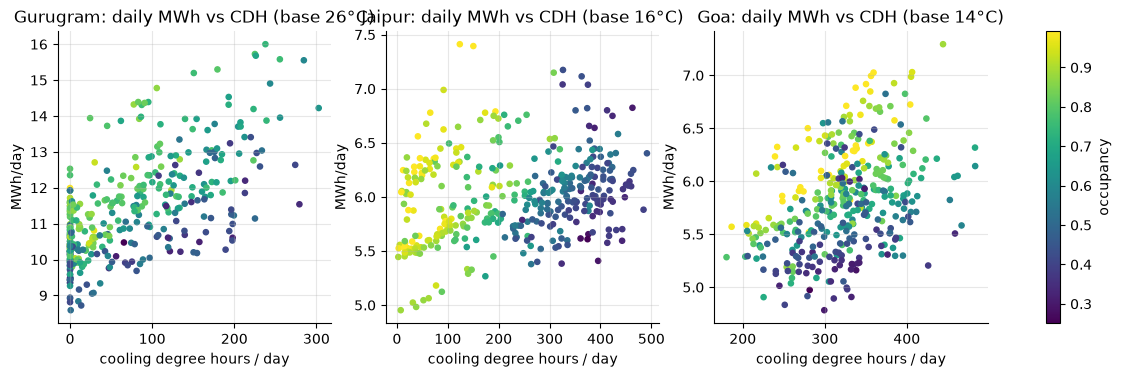

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, sc in zip(axes, ["GGN", "JAI", "GOA"]):
    d = daily[(daily.site == sc) & ~daily.excl]
    sc_ = ax.scatter(d.cdh, d.total_kwh / 1000, c=d.rooms_sold / d.rooms_available, cmap="viridis", s=14)
    ax.set_title(f"{SITES[sc]}: daily MWh vs CDH (base {best[sc]}°C)"); ax.set_xlabel("cooling degree hours / day"); ax.set_ylabel("MWh/day")
plt.colorbar(sc_, ax=axes, label="occupancy"); plt.show()

### Event effect — evening load on event days vs comparable non-event days (same site, same day type, same temperature band)

In [9]:
ev_eve = U[(U.hour.between(18, 22))].groupby(["site", "date"]).agg(eve_kw=("kw_avg", "mean"), dg=("is_dg", "max"), excl=("exclude_from_model", "max")).reset_index()
ev_eve = ev_eve.merge(daily[["site", "date", "event_guests", "temp_max", "weekend"]], on=["site", "date"])
ev_eve = ev_eve[~ev_eve.dg & ~ev_eve.excl]
ev_eve["event_band"] = pd.cut(ev_eve.event_guests, [-1, 0, 150, 300, 5000], labels=["none", "<=150", "150-300", ">300"])
ev_eve["temp_band"] = pd.cut(ev_eve.temp_max, [-10, 20, 30, 38, 60], labels=["<20", "20-30", "30-38", ">38"])
tbl = ev_eve.groupby(["site", "event_band"], observed=True).eve_kw.agg(["mean", "count"]).round(0).unstack(0)
display(tbl)
base = ev_eve[ev_eve.event_band == "none"].groupby(["site", "temp_band", "weekend"], observed=True).eve_kw.mean().rename("none_kw")
x = ev_eve[ev_eve.event_band != "none"].join(base, on=["site", "temp_band", "weekend"])
x["uplift_kw"] = x.eve_kw - x.none_kw
display(x.groupby(["site", "event_band"], observed=True).uplift_kw.agg(["mean", "median", "count"]).round(0))

mean               count          
site          GGN    GOA    JAI   GGN  GOA  JAI
event_band                                     
none       498.00 251.00 260.00   195  309  257
<=150      514.00 323.00 256.00    49    8   28
150-300    531.00 324.00 313.00    69   17    7
>300       594.00 344.00 338.00    43   22   64

mean  median  count
site event_band                      
GGN  <=150       13.00    1.00     49
     150-300     24.00   15.00     69
     >300       112.00  123.00     43
GOA  <=150       72.00   67.00      8
     150-300     70.00   69.00     17
     >300        90.00   89.00     22
JAI  <=150       -3.00   -4.00     28
     150-300     73.00   70.00      7
     >300        93.00   94.00     64

## 5 · Equipment breakdown — where the kWh goes, by season

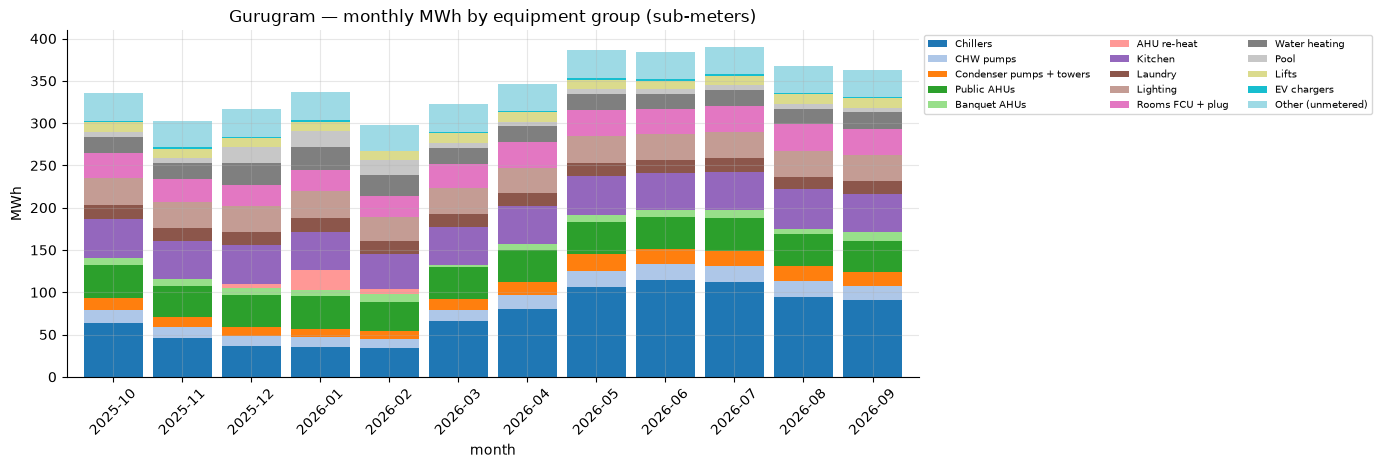

season,Autumn,Monsoon,Spring,Summer,Winter
Chillers,17.10,26.60,21.90,28.60,11.20
Kitchen,14.20,12.20,13.30,11.70,14.00
Public AHUs,11.80,10.10,11.30,9.80,11.70
Other (unmetered),10.10,8.70,9.60,8.30,10.00
Lighting,9.80,8.40,9.00,8.00,9.70
Rooms FCU + plug,8.90,8.30,8.70,7.90,7.90
Condenser pumps + towers,4.10,4.70,4.20,4.90,3.10
CHW pumps,4.50,4.90,4.50,4.90,3.60
Water heating,6.10,5.00,5.80,4.70,8.10
Laundry,4.90,4.10,4.70,4.00,4.90


Gurugram HVAC share May–Aug (chillers+pumps+towers+AHUs): 49.8%  (brief: ~50%)


In [10]:
G_GROUPS = {
    "Chillers": ["chiller_ch1_kw", "chiller_ch2_kw", "chiller_ch3_kw"],
    "CHW pumps": ["chw_pumps_kw"], "Condenser pumps + towers": ["cw_pumps_ct_kw"],
    "Public AHUs": ["ahu_public_kw"], "Banquet AHUs": ["ahu_banquet_kw"], "AHU re-heat": ["ahu_heaters_kw"],
    "Kitchen": ["kitchen_kw", "kitchen_exhaust_mua_kw"], "Laundry": ["laundry_kw"], "Lighting": ["lighting_public_kw"],
    "Rooms FCU + plug": ["rooms_fcu_plug_kw"], "Water heating": ["water_heating_kw"], "Pool": ["pool_kw"], "Lifts": ["lifts_kw"],
    "EV chargers": ["ev_chargers_kw"], "Other (unmetered)": ["other_kw"],
}
sg = sub_g.copy(); sg["month"] = sg.timestamp.dt.to_period("M").astype(str); sg["season"] = sg.timestamp.dt.month.map(season)
for k, cols in G_GROUPS.items():
    sg[k] = sg[cols].sum(axis=1)
mon_g = sg.groupby("month")[list(G_GROUPS)].sum() / 1000
ax = mon_g.plot.bar(stacked=True, figsize=(11, 4.5), colormap="tab20", width=.85, title="Gurugram — monthly MWh by equipment group (sub-meters)")
ax.set_ylabel("MWh"); ax.legend(fontsize=7, ncol=3, loc="upper left", bbox_to_anchor=(1, 1)); plt.xticks(rotation=45); plt.show()

share = sg.groupby("season")[list(G_GROUPS)].sum(); share = share.div(share.sum(axis=1), axis=0) * 100
display(share.T.round(1).sort_values("Summer", ascending=False))
mj = sg[sg.timestamp.dt.month.between(5, 8)]
hvac_cols = G_GROUPS["Chillers"] + ["chw_pumps_kw", "cw_pumps_ct_kw", "ahu_public_kw", "ahu_banquet_kw"]
print(f"Gurugram HVAC share May–Aug (chillers+pumps+towers+AHUs): {mj[hvac_cols].sum().sum() / mj[[c for g in G_GROUPS.values() for c in g]].sum().sum():.1%}  (brief: ~50%)")

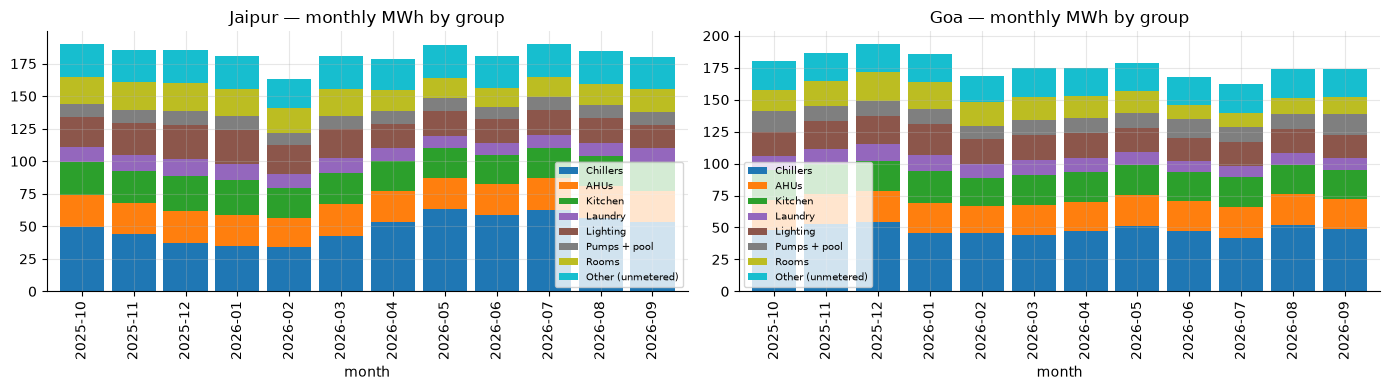


Jaipur share by season (%)


season,Autumn,Monsoon,Spring,Summer,Winter
Chillers,25.00,31.00,26.70,33.00,20.10
AHUs,12.80,13.00,13.40,12.80,13.30
Kitchen,13.30,12.50,13.00,12.40,14.30
Laundry,6.30,5.40,6.00,5.00,7.00
Lighting,12.80,10.10,11.30,10.00,14.00
Pumps + pool,5.40,5.50,5.60,5.40,5.60
Rooms,11.20,9.00,10.20,8.00,11.70
Other (unmetered),13.30,13.50,13.80,13.40,13.90


Jaipur cooling (chillers+AHUs) share May–Aug: 45.2%

Goa share by season (%)


season,Autumn,Monsoon,Spring,Summer,Winter
Chillers,27.60,28.10,26.10,28.60,26.50
AHUs,12.80,13.90,13.40,13.50,12.60
Kitchen,12.80,13.50,13.30,13.20,12.70
Laundry,6.10,5.50,6.40,5.60,6.80
Lighting,11.30,10.80,11.40,10.60,12.00
Pumps + pool,7.50,7.90,6.60,7.60,6.20
Rooms,10.00,7.30,10.20,8.20,11.40
Other (unmetered),12.00,13.00,12.60,12.70,11.80


Goa cooling (chillers+AHUs) share May–Aug: 42.2%


In [11]:
JG = {"Chillers": ["chillers_kw"], "AHUs": ["ahu_kw"], "Kitchen": ["kitchen_kw"], "Laundry": ["laundry_kw"], "Lighting": ["lighting_kw"],
      "Pumps + pool": ["pumps_pool_kw"], "Rooms": ["rooms_kw"], "Other (unmetered)": ["other_kw"]}
sj = sub_jg.copy(); sj["month"] = sj.timestamp.dt.to_period("M").astype(str); sj["season"] = sj.timestamp.dt.month.map(season)
for k, cols in JG.items(): sj[k] = sj[cols].sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, sc in zip(axes, ["JAI", "GOA"]):
    (sj[sj.site == sc].groupby("month")[list(JG)].sum() / 1000).plot.bar(stacked=True, ax=ax, colormap="tab10", width=.85, title=f"{SITES[sc]} — monthly MWh by group")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
for sc in ["JAI", "GOA"]:
    q = sj[sj.site == sc].groupby("season")[list(JG)].sum(); q = q.div(q.sum(axis=1), axis=0) * 100
    print(f"\n{SITES[sc]} share by season (%)"); display(q.T.round(1))
    print(f"{SITES[sc]} cooling (chillers+AHUs) share May–Aug: {sj[(sj.site==sc)&sj.timestamp.dt.month.between(5,8)][['Chillers','AHUs']].sum().sum() / sj[(sj.site==sc)&sj.timestamp.dt.month.between(5,8)][list(JG)].sum().sum():.1%}")

## 6 · Chiller plant behaviour (Gurugram)
Efficiency (kW/TR), how many chillers run, and what the night base load looks like — the normal against which staging and setpoint waste will be judged.

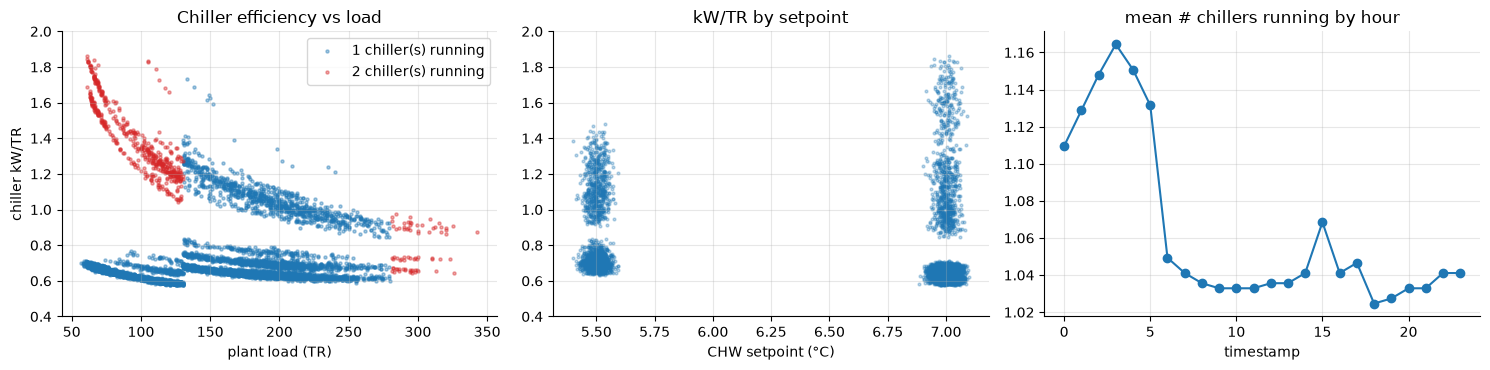

setpoint hours: {7.0: 6848, 5.5: 1912}
                hours  kw_per_tr  load_tr
chw_setpoint_c                           
5.50             1912       0.72   182.00
7.00             6848       0.66   105.00


median         count       
chillers_running      1    2        1      2
load_band                                   
<100               0.67 1.56 3,126.00 228.00
100-130            0.60 1.24   980.00 256.00
130-200            0.67  NaN 2,689.00    NaN
200-280            0.68  NaN 1,408.00    NaN
280+                NaN 0.73      NaN  73.00

CH-2 total kWh in sub-meters over the year: 0.0 (register lists CH-2 as a 300 TR chiller; it never runs here, CH-1 + CH-3 carry the load)


In [12]:
sgp = sub_g[(sub_g.chiller_load_tr > 0)].copy()
sgp["kw"] = sgp[["chiller_ch1_kw", "chiller_ch2_kw", "chiller_ch3_kw"]].sum(axis=1)
sgp["kw_per_tr"] = sgp.kw / sgp.chiller_load_tr
sgp["plant_kw"] = sgp.kw + sgp.chw_pumps_kw + sgp.cw_pumps_ct_kw
sgp["plant_kw_per_tr"] = sgp.plant_kw / sgp.chiller_load_tr
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for n, c in ((1, "#1f77b4"), (2, "#d62728")):
    d = sgp[sgp.chillers_running == n]; axes[0].scatter(d.chiller_load_tr, d.kw_per_tr, s=5, alpha=.4, c=c, label=f"{n} chiller(s) running")
axes[0].set_ylim(.4, 2); axes[0].set_xlabel("plant load (TR)"); axes[0].set_ylabel("chiller kW/TR"); axes[0].legend(); axes[0].set_title("Chiller efficiency vs load")
axes[1].scatter(sgp.chw_setpoint_c + np.random.default_rng(0).normal(0, .03, len(sgp)), sgp.kw_per_tr, s=4, alpha=.3); axes[1].set_ylim(.4, 2)
axes[1].set_xlabel("CHW setpoint (°C)"); axes[1].set_title("kW/TR by setpoint")
sgp.groupby(sgp.timestamp.dt.hour).chillers_running.mean().plot(ax=axes[2], marker="o"); axes[2].set_title("mean # chillers running by hour"); plt.tight_layout(); plt.show()
print("setpoint hours:", sub_g.chw_setpoint_c.value_counts().to_dict())
print(sgp.groupby("chw_setpoint_c").agg(hours=("kw_per_tr", "size"), kw_per_tr=("kw_per_tr", "median"), load_tr=("chiller_load_tr", "median")).round(3))
sgp["load_band"] = pd.cut(sgp.chiller_load_tr, [0, 100, 130, 200, 280, 350], labels=["<100", "100-130", "130-200", "200-280", "280+"])
display(sgp.pivot_table(index="load_band", columns="chillers_running", values="kw_per_tr", aggfunc=["median", "count"], observed=True).round(3))
print("CH-2 total kWh in sub-meters over the year:", float(sub_g.chiller_ch2_kw.sum()), "(register lists CH-2 as a 300 TR chiller; it never runs here, CH-1 + CH-3 carry the load)")

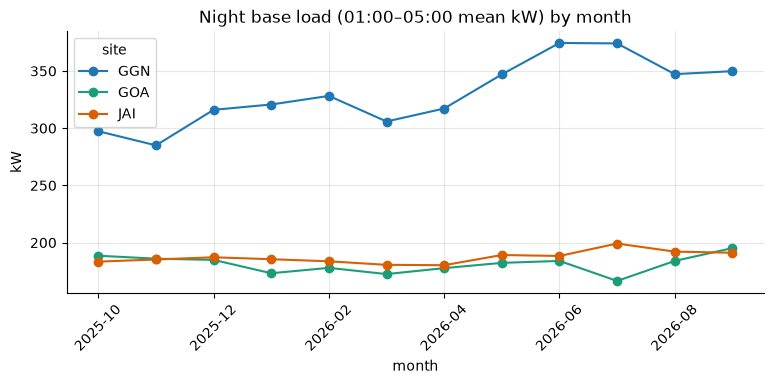

In [13]:
nb = U[(U.hour.between(1, 4)) & ~U.exclude_from_model & ~U.is_dg].groupby(["site", "month"]).kw_avg.mean().unstack(0)
ax = nb.plot(figsize=(9, 3.4), marker="o", color=[COL[c] for c in nb.columns], title="Night base load (01:00–05:00 mean kW) by month"); ax.set_ylabel("kW"); plt.xticks(rotation=45); plt.show()

## 7 · The bill — where the money goes

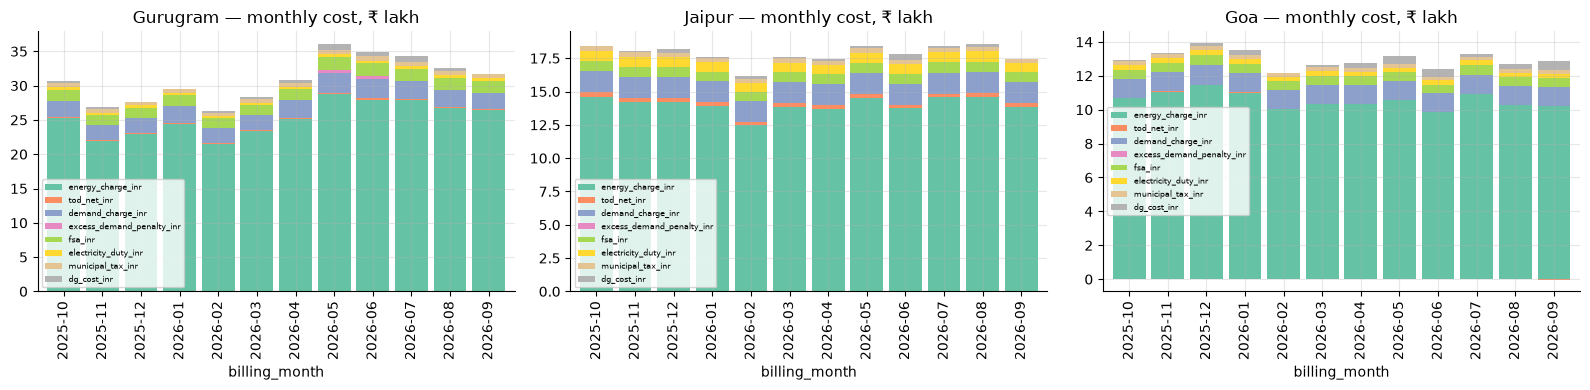

,energy_charge_inr,tod_net_inr,demand_charge_inr,excess_demand_penalty_inr,fsa_inr,electricity_duty_inr,municipal_tax_inr,dg_cost_inr,total_energy_cost_inr
site,,,,,,,,,
GGN,302.30,1.80,29.20,0.90,20.00,4.30,6.60,4.70,369.90
GOA,126.70,-0.00,13.50,0.00,6.60,3.30,2.80,2.80,155.90
JAI,168.20,3.50,18.90,0.00,9.00,9.00,3.70,2.00,214.20


,energy_charge_inr,tod_net_inr,demand_charge_inr,excess_demand_penalty_inr,fsa_inr,electricity_duty_inr,municipal_tax_inr,dg_cost_inr
site,,,,,,,,
GGN,81.70,0.50,7.90,0.20,5.40,1.20,1.80,1.30
GOA,81.30,-0.00,8.70,0.00,4.20,2.10,1.80,1.80
JAI,78.50,1.60,8.80,0.00,4.20,4.20,1.70,0.90


Annual total ₹ crore: {'GGN': 3.7, 'GOA': 1.56, 'JAI': 2.14} | sum: 7.4 (brief: 3.70 / 2.14 / 1.56 = 7.40)


site,GGN,GOA,JAI
billing_month,,,
2025-10,8.52,6.98,9.44
2025-11,8.58,6.97,9.47
2025-12,8.53,6.95,9.46
2026-01,8.58,6.98,9.48
2026-02,8.58,7.04,9.58
2026-03,8.53,7.01,9.47
2026-04,8.60,7.01,9.48
2026-05,8.72,6.99,9.43
2026-06,8.70,7.03,9.47


In [14]:
comps = ["energy_charge_inr", "tod_net_inr", "demand_charge_inr", "excess_demand_penalty_inr", "fsa_inr", "electricity_duty_inr", "municipal_tax_inr", "dg_cost_inr"]
bb = bills.copy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, sc in zip(axes, ["GGN", "JAI", "GOA"]):
    d = bb[bb.site == sc].set_index("billing_month")[comps] / 1e5
    d.plot.bar(stacked=True, ax=ax, colormap="Set2", width=.85, title=f"{SITES[sc]} — monthly cost, ₹ lakh"); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()
ann = bb.groupby("site")[comps + ["total_energy_cost_inr"]].sum() / 1e5
share = ann[comps].div(ann.total_energy_cost_inr, axis=0) * 100
display(ann.round(1)); display(share.round(1))
print("Annual total ₹ crore:", (ann.total_energy_cost_inr / 100).round(2).to_dict(), "| sum:", round(ann.total_energy_cost_inr.sum() / 100, 2), "(brief: 3.70 / 2.14 / 1.56 = 7.40)")
bb["eff_inr_per_kvah"] = bb.total_grid_bill_inr / bb.grid_kvah
bb["billing_dem_vs_cd"] = bb.billing_demand_kva / bb.contract_demand_kva
display(bb.pivot(index="billing_month", columns="site", values="eff_inr_per_kvah").round(2))

In [15]:
# Gurugram April -> May 2026: what changed on the bill, and what changed in the world
cmp = bb[(bb.site == "GGN") & bb.billing_month.isin(["2026-04", "2026-05"])].set_index("billing_month")
delta = (cmp.loc["2026-05", comps + ["total_energy_cost_inr"]] - cmp.loc["2026-04", comps + ["total_energy_cost_inr"]])
ctx = daily[daily.site == "GGN"].groupby("month").agg(kvah=("grid_kvah", "sum"), occupied=("rooms_sold", "sum"), event_guests=("event_guests", "sum"),
                                                     cdh=("cdh", "sum"), max_temp=("temp_max", "max"), mean_temp=("temp_mean", "mean"), max_kva=("max_kva", "max")).loc[["2026-04", "2026-05"]]
print("Bill delta May − April (₹):"); display(delta.to_frame("delta_inr").round(0))
print("Driver context:"); display(ctx.T)
print(f"Of the ₹{delta['total_energy_cost_inr']:,.0f} increase: energy+FSA+duty+tax (volume) ≈ ₹{delta[['energy_charge_inr','fsa_inr','electricity_duty_inr','municipal_tax_inr']].sum():,.0f}, "
      f"demand penalty ₹{delta['excess_demand_penalty_inr']:,.0f}, demand charge ₹{delta['demand_charge_inr']:,.0f}, ToD ₹{delta['tod_net_inr']:,.0f}, diesel ₹{delta['dg_cost_inr']:,.0f}")

Bill delta May − April (₹):


,delta_inr
energy_charge_inr,360882
tod_net_inr,1279
demand_charge_inr,35351
excess_demand_penalty_inr,49880
fsa_inr,23889
electricity_duty_inr,5083
municipal_tax_inr,7924
dg_cost_inr,46028
total_energy_cost_inr,530316


Driver context:


month,2026-04,2026-05
kvah,"353,470.07","404,298.42"
occupied,"4,765.00","4,514.00"
event_guests,"2,309.00","3,649.00"
cdh,"2,778.80","5,856.30"
max_temp,39.90,43.70
mean_temp,28.92,33.85
max_kva,878.10,"1,086.00"


Of the ₹530,316 increase: energy+FSA+duty+tax (volume) ≈ ₹397,778, demand penalty ₹49,880, demand charge ₹35,351, ToD ₹1,279, diesel ₹46,028


## 8 · Time-of-day tariff exposure
Windows differ by hotel (tariffs sheet): **GGN** peak 18–22 (+₹1.00) / off-peak 23–05 (−₹0.75); **JAI** peak 17–23 (+₹1.125) / off-peak 23–05 (−₹0.75);
**GOA** peak 18–22 (+₹0.75) / off-peak 22–06 (−₹0.50).

window,normal,off-peak,peak,brief_peak_share
site,,,,
GGN,63.10,18.70,18.30,18.30
GOA,54.60,27.30,18.10,NaN
JAI,53.50,19.70,26.80,26.80


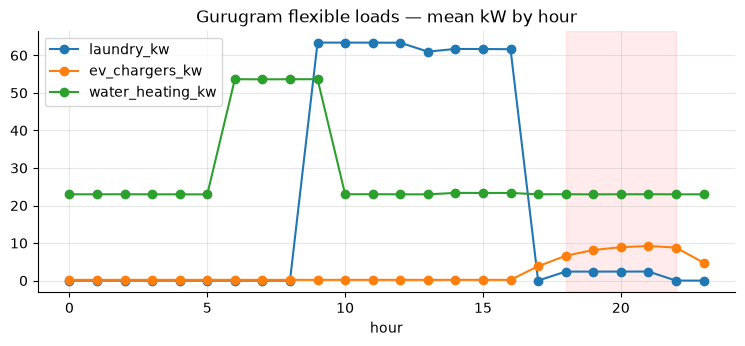

Share of flexible-load kWh falling in the 18–22 peak window:
{'laundry_kw': 1.9, 'ev_chargers_kw': 61.3, 'water_heating_kw': 13.6}


In [16]:
TOD = {"GGN": ((18, 22), (23, 5)), "JAI": ((17, 23), (23, 5)), "GOA": ((18, 22), (22, 6))}
def tod_window(r_site, hour):
    (ps, pe), (os_, oe) = TOD[r_site]
    if ps <= hour < pe: return "peak"
    if hour >= os_ or hour < oe: return "off-peak"
    return "normal"
hh = U.copy()
hh["window"] = [tod_window(s, h) for s, h in zip(hh.site, hh.hour)]
tw = hh.groupby(["site", "window"]).grid_kvah.sum().unstack().pipe(lambda d: d.div(d.sum(axis=1), axis=0) * 100)
tw["brief_peak_share"] = pd.Series({"GGN": 18.3, "JAI": 26.8})
display(tw.round(1))
flex = sub_g.assign(hour=sub_g.timestamp.dt.hour)
fl = flex.groupby("hour")[["laundry_kw", "ev_chargers_kw", "water_heating_kw"]].mean()
ax = fl.plot(figsize=(9, 3.4), marker="o", title="Gurugram flexible loads — mean kW by hour"); ax.axvspan(18, 22, color="red", alpha=.08); plt.show()
print("Share of flexible-load kWh falling in the 18–22 peak window:"); print((fl.loc[18:21].sum() / fl.sum() * 100).round(1).to_dict())

## 9 · Gurugram peak demand (kVA, 15-min)

In [17]:
pk = g15.set_index("timestamp").kva_demand
msum = pd.DataFrame({"MD kVA": pk.resample("MS").max(), ">920 (EV throttle) intervals": (pk > 920).resample("MS").sum(), ">1000 (CD) intervals": (pk > 1000).resample("MS").sum()})
msum.index = msum.index.strftime("%Y-%m"); display(msum)
top = pk[pk > 900].to_frame("kva"); top["hour"] = top.index.hour; top["date"] = top.index.normalize()
top = top.merge(daily[daily.site == "GGN"][["date", "temp_max", "event_guests", "rooms_sold"]], on="date", how="left").set_index(top.index)
print(f"{len(top)} intervals above 900 kVA on {top.date.nunique()} days")
display(top.groupby("date").agg(max_kva=("kva", "max"), at_hour=("hour", lambda x: x.mode().iat[0]), temp_max=("temp_max", "first"), event_guests=("event_guests", "first"), rooms_sold=("rooms_sold", "first")).sort_values("max_kva", ascending=False).head(15).round(0))
print("hour-of-day of intervals >900 kVA:", top.hour.value_counts().sort_index().to_dict())

,MD kVA,>920 (EV throttle) intervals,>1000 (CD) intervals
timestamp,,,
2025-10,790.30,0,0
2025-11,734.20,0,0
2025-12,714.90,0,0
2026-01,851.80,0,0
2026-02,698.00,0,0
2026-03,704.70,0,0
2026-04,878.10,0,0
2026-05,"1,086.00",12,7
2026-06,"1,066.10",21,5


39 intervals above 900 kVA on 6 days


,max_kva,at_hour,temp_max,event_guests,rooms_sold
date,,,,,
2026-05-12,"1,086.00",14,42.00,103.00,176
2026-06-18,"1,066.00",14,41.00,170.00,159
2026-06-25,"1,032.00",14,39.00,275.00,164
2026-05-21,916.00,14,41.00,317.00,177
2026-05-11,903.00,15,44.00,247.00,171
2026-06-17,902.00,12,42.00,220.00,168


hour-of-day of intervals >900 kVA:

 {12: 1, 14: 13, 15: 13, 16: 12}


## 10 · Takeaways for the build
**Reconciliation with the brief** — energy per occupied room-night (73.3 / 54.1 / 61.6), annual cost (₹3.70 / 2.14 / 1.56 crore),
Gurugram HVAC share May–Aug (49.8% vs "about half") and the Gurugram peak-window share (18.3%) all reproduce, so the cleaned data and the
engineered Gurugram hourly feature are consistent with the problem owner's numbers. The Gurugram hourly MD matches the bills to within 0.5 kVA.

**Where the energy goes** — cooling dominates and is the seasonal swing: Gurugram chillers are 11% of load in winter but 29% in summer; Jaipur 20% → 33%.
Goa is flat year-round (26–29%) because it is humid all year, not hot. Winter adds Gurugram re-heat (3.6%) and pool (5.9%), water heating (8%).
Kitchen (12–14%), lighting (8–10%) and rooms (8–9%) are steady base loads. About 8–14% in each hotel is unmetered "other".

**Where the money goes** — ~80% of each bill is the energy charge on kVAh; demand charge ~8%, FSA 4–5%. ToD nets to almost nothing because the
peak surcharge and off-peak rebate roughly cancel, so *kVAh volume and power factor* are the levers, not tariff-window arbitrage (except for kVA demand).
Gurugram's ₹0.9 lakh penalty is confined to May and June 2026 (₹49,880 in May); no other month exceeds contract demand.

**Drivers** — daily load is explained ~70% by cooling degree hours, rooms sold, event guests and weekend (R² 0.69–0.72 incl. humidity);
base temperature differs by hotel (best CDH base: Gurugram 26 °C, Jaipur 16, Goa 14), and humidity adds most in Goa (R² 0.69 → 0.75).
Events are a large, clean signal: a >300-guest event adds ~110–120 kW to Gurugram's 18–22 average (≈ +20%), ~90 kW in Goa and Jaipur.
So the baseline must carry event guests (and their timing), or every wedding becomes a false alarm (T2).

**Chiller plant** — one chiller runs at ~0.60–0.68 kW/TR; two running below ~130 TR is 1.2–1.6 kW/TR (about double) — 484 hours, the staging-waste
signature. The register lists CH-2 (300 TR) but the sub-meter shows 0 kWh all year: CH-1 + CH-3 carry everything, so "two large chillers" is
CH-1 + CH-3 here; treat as a data/labelling quirk to raise with the problem owner. The 5.5 °C setpoint (1,912 h) costs ~0.72 vs 0.66 kW/TR median.

**Peak demand** — Gurugram's >900 kVA intervals occur on only 6 days, all hot afternoons (12:00–16:00, 39–44 °C), not evening events; all six are in May–June. Evening wedding load is large (+110 kW) but doesn't reach the contract limit on its own. The EV throttle threshold (920 kVA) would have
fired only ~33 intervals all year. 61% of EV charging kWh falls in the 18–22 peak window; laundry is 2% (already off-peak on average).

**Tariff detail** — ToD windows differ by hotel (Jaipur peak 17–23, Goa off-peak 22–06). With each hotel's own windows Jaipur's peak-window share is 26.8%, matching the brief
(Gurugram 18.3%); using Gurugram's 18–22 window for Jaipur would wrongly give 18%.

**Caveats for modelling** — hourly/daily R² ≈ 0.7 is only a starting point (no lags, no hour-of-day, no thermal inertia); the real baseline will need
hourly models with day-type × hour interactions. Remember `exclude_from_model` rows (Gurugram fault hours) and the Jaipur imputed hours.